# Experiment 7 — Sentiment Classification on IMDb

## Objective
Implement and compare multiple sentiment-classification approaches on the IMDb Large Movie Review Dataset:

1. Logistic Regression with TF-IDF
2. LSTM neural network
3. Vanilla Transformer encoder
4. Pre-trained DistilBERT

The models are compared using **Accuracy, Precision, Recall, and F1-score**.

> **Runtime:** Google Colab with a T4 GPU is recommended.  
> **External data:** None needs to be uploaded manually. The IMDb dataset and DistilBERT weights are downloaded automatically.


In [1]:
# Setup and reproducibility
!pip -q install transformers

import os
import re
import html
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. The notebook will run on CPU, but neural models will be slower.")


Device: cuda
GPU: Tesla T4


## 1. Download and Load the IMDb Dataset

The Stanford Large Movie Review Dataset contains **50,000 labeled reviews**:
25,000 official training reviews and 25,000 official test reviews.

The notebook downloads and extracts it automatically.


In [2]:
DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
ARCHIVE = Path("aclImdb_v1.tar.gz")
DATA_DIR = Path("aclImdb")

if not DATA_DIR.exists():
    if not ARCHIVE.exists():
        print("Downloading IMDb dataset...")
        urllib.request.urlretrieve(DATA_URL, ARCHIVE)

    print("Extracting dataset...")
    with tarfile.open(ARCHIVE, "r:gz") as tar:
        # Python 3.12+ supports the safer data filter.
        try:
            tar.extractall(filter="data")
        except TypeError:
            tar.extractall()

def load_reviews(split):
    rows = []
    for label_name, label in [("neg", 0), ("pos", 1)]:
        folder = DATA_DIR / split / label_name
        for path in sorted(folder.glob("*.txt")):
            rows.append((path.read_text(encoding="utf-8"), label))
    return pd.DataFrame(rows, columns=["review", "label"])

official_train = load_reviews("train")
test_df = load_reviews("test")

# Create validation only from the official training split.
train_df, val_df = train_test_split(
    official_train,
    test_size=0.10,
    random_state=SEED,
    stratify=official_train["label"],
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
display(train_df.head())


Extracting dataset...
Train: 22500
Validation: 2500
Test: 25000


,review,label
6740,When you're making a thriller about witchcraft...,0
8635,"This is not a commentary on the actual movie, ...",0
17340,Having not seen the films before (and not bein...,1
2303,***SPOILERS*** With a gathering of family memb...,0
6014,I see where a few people involved in this deba...,0


## 2. Text Cleaning

For TF-IDF and the custom neural models, reviews are normalized by removing HTML markup,
lowercasing, removing non-letter characters, and collapsing whitespace.

DistilBERT later receives the **original review text**, because its tokenizer performs its own preprocessing.


In [3]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for frame in (train_df, val_df, test_df):
    frame["clean_review"] = frame["review"].map(clean_text)

print(train_df[["clean_review", "label"]].head())


                                            clean_review  label
6740   when you're making a thriller about witchcraft...      0
8635   this is not a commentary on the actual movie b...      0
17340  having not seen the films before and not being...      1
2303   spoilers with a gathering of family members an...      0
6014   i see where a few people involved in this deba...      0


## 3. Logistic Regression — TF-IDF Baseline


In [4]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

X_train = tfidf.fit_transform(train_df["clean_review"])
X_test = tfidf.transform(test_df["clean_review"])

lr_model = LogisticRegression(max_iter=1000, random_state=SEED)
lr_model.fit(X_train, train_df["label"])
lr_preds = lr_model.predict(X_test)

print(classification_report(test_df["label"], lr_preds, digits=4))


              precision    recall  f1-score   support

           0     0.9035    0.8925    0.8979     12500
           1     0.8938    0.9046    0.8992     12500

    accuracy                         0.8986     25000
   macro avg     0.8986    0.8986    0.8986     25000
weighted avg     0.8986    0.8986    0.8986     25000



## 4. Prepare Sequences for LSTM and Transformer

To keep the Colab experiment practical, the neural models use the most frequent **20,000 words**
and reviews are truncated/padded to **200 tokens**.


In [5]:
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 200

counter = Counter()
for text in train_df["clean_review"]:
    counter.update(text.split())

word_to_id = {"<PAD>": 0, "<UNK>": 1}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    word_to_id[word] = len(word_to_id)

def encode(text):
    ids = [word_to_id.get(w, 1) for w in text.split()[:MAX_LEN]]
    ids += [0] * (MAX_LEN - len(ids))
    return ids

class ReviewDataset(Dataset):
    def __init__(self, frame):
        self.x = np.asarray([encode(t) for t in frame["clean_review"]], dtype=np.int64)
        self.y = frame["label"].to_numpy(dtype=np.int64)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return torch.tensor(self.x[idx]), torch.tensor(self.y[idx])

train_loader = DataLoader(ReviewDataset(train_df), batch_size=128, shuffle=True)
val_loader = DataLoader(ReviewDataset(val_df), batch_size=256)
test_loader = DataLoader(ReviewDataset(test_df), batch_size=256)

print("Vocabulary size:", len(word_to_id))


Vocabulary size: 20000


In [6]:
def train_model(model, epochs=2, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)

        model.eval()
        correct = total = 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = model(x).argmax(dim=1)
                correct += (pred == y).sum().item()
                total += len(y)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train loss: {total_loss / len(train_df):.4f} | "
            f"Val accuracy: {correct / total:.4f}"
        )

    return model

def predict_model(model):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            preds.extend(model(x).argmax(dim=1).cpu().numpy())
    return np.asarray(preds)


## 5. LSTM Sentiment Classifier


In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        emb = self.embedding(x)
        _, (h, _) = self.lstm(emb)
        return self.fc(self.dropout(h[-1]))

lstm_model = LSTMClassifier(len(word_to_id))
lstm_model = train_model(lstm_model, epochs=2, lr=1e-3)
lstm_preds = predict_model(lstm_model)

print(classification_report(test_df["label"], lstm_preds, digits=4))


Epoch 1/2 | Train loss: 0.6935 | Val accuracy: 0.5156
Epoch 2/2 | Train loss: 0.6884 | Val accuracy: 0.5028
              precision    recall  f1-score   support

           0     0.5412    0.1466    0.2307     12500
           1     0.5065    0.8758    0.6418     12500

    accuracy                         0.5112     25000
   macro avg     0.5238    0.5112    0.4362     25000
weighted avg     0.5238    0.5112    0.4362     25000



## 6. Vanilla Transformer Sentiment Classifier


In [8]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, max_len=MAX_LEN, d_model=128, nhead=4, layers=2):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.position_embedding = nn.Embedding(max_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=0.2,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=layers)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(d_model, 2)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        h = self.token_embedding(x) + self.position_embedding(positions)

        padding_mask = x.eq(0)
        h = self.encoder(h, src_key_padding_mask=padding_mask)

        valid = (~padding_mask).unsqueeze(-1)
        pooled = (h * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1)

        return self.fc(self.dropout(pooled))

transformer_model = TransformerClassifier(len(word_to_id))
transformer_model = train_model(transformer_model, epochs=2, lr=5e-4)
transformer_preds = predict_model(transformer_model)

print(classification_report(test_df["label"], transformer_preds, digits=4))


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


Epoch 1/2 | Train loss: 0.5943 | Val accuracy: 0.7508
Epoch 2/2 | Train loss: 0.4438 | Val accuracy: 0.7908
              precision    recall  f1-score   support

           0     0.7667    0.8388    0.8011     12500
           1     0.8221    0.7448    0.7815     12500

    accuracy                         0.7918     25000
   macro avg     0.7944    0.7918    0.7913     25000
weighted avg     0.7944    0.7918    0.7913     25000



## 7. Pre-trained DistilBERT

A DistilBERT model already fine-tuned on SST-2 sentiment data is evaluated as a pretrained
Transformer baseline. To keep the free-Colab run reasonable, evaluation uses a deterministic
**1,000-review subset** of the IMDb test set.


In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device)
bert_model.eval()

bert_test = test_df.sample(1000, random_state=SEED).reset_index(drop=True)

bert_preds = []
BERT_BATCH = 32

for start in range(0, len(bert_test), BERT_BATCH):
    texts = bert_test["review"].iloc[start:start+BERT_BATCH].tolist()
    batch = bert_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        logits = bert_model(**batch).logits

    bert_preds.extend(logits.argmax(dim=1).cpu().numpy())

bert_preds = np.asarray(bert_preds)

print(classification_report(bert_test["label"], bert_preds, digits=4))


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

              precision    recall  f1-score   support

           0     0.8398    0.8924    0.8653       511
           1     0.8796    0.8221    0.8499       489

    accuracy                         0.8580      1000
   macro avg     0.8597    0.8572    0.8576      1000
weighted avg     0.8593    0.8580    0.8578      1000



## 8. Comparative Performance Analysis

The first three models are evaluated on all 25,000 official IMDb test reviews.
DistilBERT is evaluated on the deterministic 1,000-review subset noted above.


,Accuracy,Precision,Recall,F1
Logistic Regression,0.8986,0.8938,0.9046,0.8992
LSTM,0.5112,0.5065,0.8758,0.6418
Vanilla Transformer,0.7918,0.8221,0.7448,0.7815
DistilBERT (1K subset),0.8580,0.8796,0.8221,0.8499


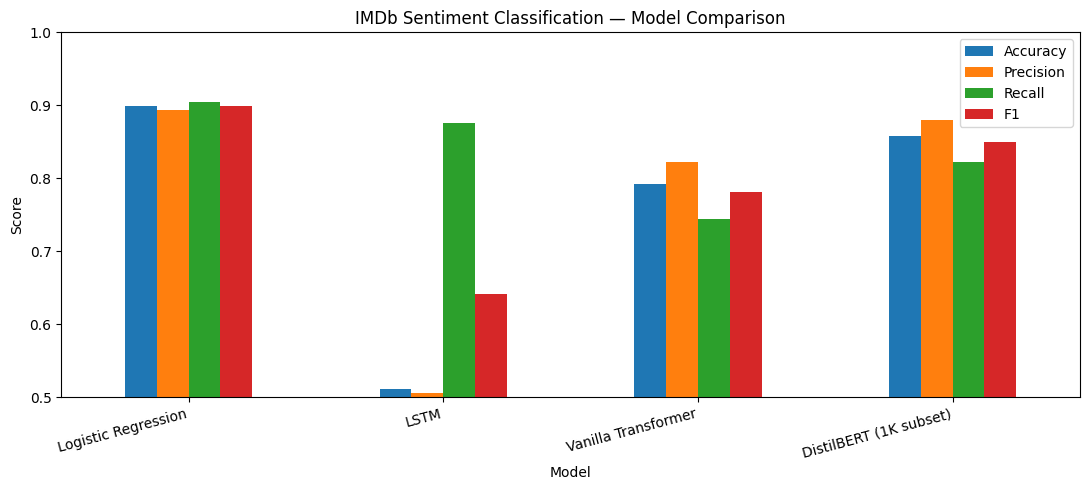

In [10]:
def metric_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

metrics_df = pd.DataFrame({
    "Logistic Regression": metric_row(test_df["label"], lr_preds),
    "LSTM": metric_row(test_df["label"], lstm_preds),
    "Vanilla Transformer": metric_row(test_df["label"], transformer_preds),
    "DistilBERT (1K subset)": metric_row(bert_test["label"], bert_preds),
}).T

display(metrics_df.round(4))

ax = metrics_df.plot(kind="bar", figsize=(11, 5), ylim=(0.5, 1.0))
ax.set_title("IMDb Sentiment Classification — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## 9. Confusion Matrices


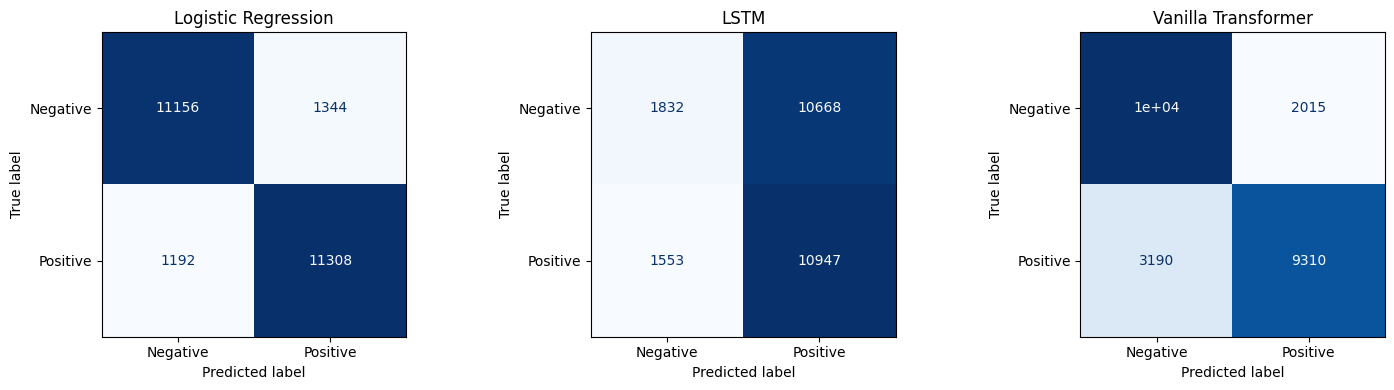

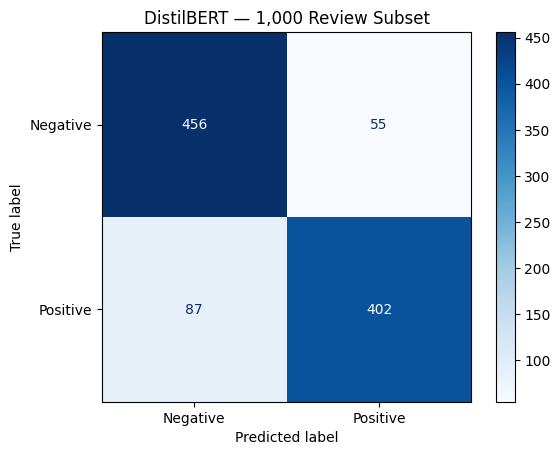

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name, preds in [
    (axes[0], "Logistic Regression", lr_preds),
    (axes[1], "LSTM", lstm_preds),
    (axes[2], "Vanilla Transformer", transformer_preds),
]:
    ConfusionMatrixDisplay.from_predictions(
        test_df["label"], preds,
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    bert_test["label"], bert_preds,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
)
plt.title("DistilBERT — 1,000 Review Subset")
plt.show()


## Conclusion

This experiment compares a classical TF-IDF baseline, recurrent neural network,
Transformer encoder, and a pretrained Transformer for sentiment classification.

The final table is generated directly from the current execution, allowing the relative
strengths of the four approaches to be compared using the same standard classification metrics.

**Note:** DistilBERT is evaluated on a 1,000-review subset for practical Colab runtime,
while the other models use the complete 25,000-review official IMDb test set.
